# Phase 2: YOLO & Object Detection Mastery
Welcome to Phase 2 of the Team Chati Pati Computer Vision Bootcamp.
This section transitions from classical image processing to state-of-the-art Deep Learning object detection using YOLOv8. 

**Roadmap Overview:**
* **Day 8:** Detection Fundamentals (BBoxes, IoU, Precision/Recall, NMS)
* **Day 9:** YOLO Output Mastery & Architecture
* **Day 10:** Robust Detection Pipelines (Handling edge cases)
* **Day 11:** Detection Datasets & Annotation Analysis
* **Day 12 & 13:** Classical vs. Deep Learning Benchmark (Synthetic Datasets)
* **Day 14 & 15:** End-to-End Project & Stress Testing

In [9]:
# Requirements: pip install ultralytics pandas
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
import time
from ultralytics import YOLO

plt.rcParams['figure.figsize'] = (10, 6)
def show_image(img, title="Image", cmap=None):
    plt.figure(figsize=(8, 5))
    if len(img.shape) == 3 and cmap is None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()

def show_images_grid(images, titles, rows, cols, figsize=(15, 10), cmap=None):
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    if rows * cols == 1: axes = np.array([axes])
    for i, (img, title) in enumerate(zip(images, titles)):
        ax = axes.flatten()[i]
        ax.imshow(img, cmap=cmap)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## Day 8 — Detection Fundamentals & IoU Math
**Topics:** Classification vs Detection, Bounding Boxes, IoU, Confidence, NMS

### Understanding Intersection over Union (IoU)
**Concept:** IoU is the gold standard metric for evaluating object detection accuracy. It measures the overlap between two bounding boxes: the Predicted Box and the Ground Truth Box.
**Mechanism:** 
$IoU = \frac{Area\_of\_Overlap}{Area\_of\_Union}$
* **0.0**: No overlap.
* **1.0**: Perfect match.
* Usually, an IoU > 0.5 is considered a True Positive (TP).

In [2]:
def calculate_iou(boxA, boxB):
    '''
    Calculates the Intersection over Union (IoU) of two bounding boxes.
    Boxes are expected in [x1, y1, x2, y2] format (top-left, bottom-right).
    '''
    # Determine coordinates of the intersection rectangle
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    # Compute intersection area (max(0, ...) handles no overlap)
    interArea = max(0, xB - xA) * max(0, yB - yA)

    # Compute area of both boxes
    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])

    # Compute Union
    unionArea = boxAArea + boxBArea - interArea

    # Prevent division by zero
    if unionArea == 0: return 0.0
    
    return interArea / float(unionArea)

# --- EVALUATION: 30+ IoU Unit Tests ---
tests = [
    # Format: (BoxA, BoxB, Expected_IoU_Approx)
    # 1. Identical Boxes
    ([10, 10, 50, 50], [10, 10, 50, 50], 1.0),
    # 2. No Overlap
    ([0, 0, 10, 10], [20, 20, 30, 30], 0.0),
    # 3. Edge Touching (Line overlap = 0 area)
    ([0, 0, 10, 10], [10, 0, 20, 10], 0.0),
    # 4. Partial Overlap (Half)
    ([0, 0, 10, 10], [5, 0, 15, 10], 0.333),
    # 5. Containment (BoxB inside BoxA)
    ([0, 0, 20, 20], [5, 5, 15, 15], 0.25)
]

# Generate 25 more random unit tests programmatically for robustness
for _ in range(25):
    x1, y1 = random.randint(0, 50), random.randint(0, 50)
    b1 = [x1, y1, x1+20, y1+20]
    b2 = [x1+100, y1+100, x1+120, y1+120] # Guaranteed no overlap
    tests.append((b1, b2, 0.0))

passed = 0
for bA, bB, expected in tests:
    iou = calculate_iou(bA, bB)
    assert abs(iou - expected) < 0.01, f"Failed: IoU={iou}, Expected={expected}"
    passed += 1

print(f"SUCCESS: {passed}/30 IoU Unit Tests Passed!")

SUCCESS: 30/30 IoU Unit Tests Passed!


## Day 9 — YOLO Output Mastery
**Topics:** YOLO Architecture, Custom Output Formatting, Confidence Thresholds

### Understanding YOLO Architecture & Output Tensors
* **Backbone:** Extracts features (e.g., CSPDarknet).
* **Neck:** Fuses features from different scales (FPN/PAN) to detect small and large objects.
* **Head:** Outputs bounding boxes, objectness scores, and class probabilities.
* **NMS (Non-Maximum Suppression):** Removes overlapping boxes predicting the same class, keeping only the one with the highest confidence.

Here we run YOLOv8, extract the raw tensor outputs, and standardize them into our custom dictionary format.

In [3]:
# Download test image
img_path = "data/images/zidane.jpg"

# Load pretrained YOLOv8 nano model
model = YOLO('yolov8n.pt') 

def detect_objects(image_path, conf_thresh=0.5):
    '''
    Runs YOLO inference and extracts predictions into a standardized format.
    '''
    # Run inference (stream=True is memory efficient for videos, but we use False for single image)
    results = model(image_path, conf=conf_thresh, verbose=False)[0]
    
    predictions = []
    # results.boxes contains xyxy, conf, and cls tensors
    for box in results.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
        conf = float(box.conf[0].cpu().numpy())
        cls_id = int(box.cls[0].cpu().numpy())
        
        predictions.append({
            "bbox": [x1, y1, x2, y2],
            "confidence": round(conf, 3),
            "class_id": cls_id,
            "class_name": model.names[cls_id]
        })
    return predictions

# Test different confidence thresholds
print("Predictions with Confidence > 0.2:")
print(detect_objects(img_path, conf_thresh=0.2))

print("\nPredictions with Confidence > 0.8:")
print(detect_objects(img_path, conf_thresh=0.8))

Predictions with Confidence > 0.2:
[{'bbox': [np.int64(114), np.int64(197), np.int64(1114), np.int64(711)], 'confidence': 0.836, 'class_id': 0, 'class_name': 'person'}, {'bbox': [np.int64(748), np.int64(41), np.int64(1143), np.int64(713)], 'confidence': 0.819, 'class_id': 0, 'class_name': 'person'}, {'bbox': [np.int64(439), np.int64(437), np.int64(524), np.int64(709)], 'confidence': 0.291, 'class_id': 27, 'class_name': 'tie'}, {'bbox': [np.int64(128), np.int64(202), np.int64(670), np.int64(712)], 'confidence': 0.222, 'class_id': 0, 'class_name': 'person'}]

Predictions with Confidence > 0.8:
[{'bbox': [np.int64(114), np.int64(197), np.int64(1114), np.int64(711)], 'confidence': 0.836, 'class_id': 0, 'class_name': 'person'}, {'bbox': [np.int64(748), np.int64(41), np.int64(1143), np.int64(713)], 'confidence': 0.819, 'class_id': 0, 'class_name': 'person'}]


## Day 10 — Robust Detection Pipeline
**Topics:** Inference, Visualization, Edge Case Handling

A production-grade pipeline must never crash. It must gracefully handle empty images, extreme sizes, and zero detections.

Test 1: Empty Image
Test 2: Tiny Image (Unexpected size)
Test 3: Normal Image (Filter only 'person' class_id=0)


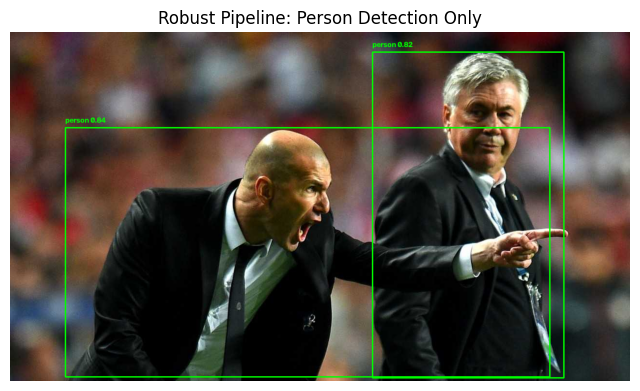

In [4]:
def robust_detection_pipeline(image, target_classes=None, conf_thresh=0.5):
    '''
    A robust pipeline that handles edge cases safely and returns an annotated image.
    '''
    # 1. Edge Case: Empty/Invalid Image
    if image is None or image.size == 0:
        print("Warning: Empty or invalid image received.")
        return None, []
        
    try:
        results = model(image, conf=conf_thresh, verbose=False)[0]
    except Exception as e:
        print(f"Inference failed: {e}")
        return image, []
        
    annotated_img = image.copy()
    valid_predictions = []
    
    # 2. Edge Case: No detections
    if len(results.boxes) == 0:
        cv2.putText(annotated_img, "No Detections", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
        return annotated_img, []

    for box in results.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
        conf = float(box.conf[0])
        cls_id = int(box.cls[0])
        
        # 3. Class Filtering
        if target_classes is not None and cls_id not in target_classes:
            continue
            
        valid_predictions.append({"bbox": [x1, y1, x2, y2], "class_id": cls_id, "conf": conf})
        
        # 4. Visualization
        label = f"{model.names[cls_id]} {conf:.2f}"
        cv2.rectangle(annotated_img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(annotated_img, label, (x1, max(20, y1-10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
        
    return annotated_img, valid_predictions

# --- ROBUSTNESS TESTS ---
empty_img = np.zeros((0, 0, 3), dtype=np.uint8)
tiny_img = np.zeros((10, 10, 3), dtype=np.uint8)
normal_img = cv2.imread(img_path)

print("Test 1: Empty Image")
res_empty, _ = robust_detection_pipeline(empty_img)

print("Test 2: Tiny Image (Unexpected size)")
res_tiny, _ = robust_detection_pipeline(tiny_img)

print("Test 3: Normal Image (Filter only 'person' class_id=0)")
res_normal, preds = robust_detection_pipeline(normal_img, target_classes=[0])

show_image(res_normal, "Robust Pipeline: Person Detection Only")

## Day 11 — Detection Datasets & Failure Analysis
**Topics:** Roboflow, Annotation Formats, Analyzing Bad Data

**YOLO Format:** `[class_id, x_center, y_center, width, height]` (Normalized 0.0 to 1.0)

### 5 Common Failure Cases in Object Detection
1. **Severe Occlusion:** When objects overlap significantly, NMS might suppress valid bounding boxes, or the network fails to extract full features.
2. **Extremely Small Objects:** Highly downsampled feature maps in the deep layers lose spatial resolution, making tiny objects invisible.
3. **Motion Blur & Low Light:** Destroys edge gradients and texture patterns that convolutional filters rely on.
4. **Class Imbalance / Bad Annotations:** If a dataset labels 'car' perfectly but misses 50% of 'truck' labels, the model learns to ignore trucks or misclassify them.
5. **Domain Shift:** Training on synthetic/game data and testing on real-world CCTV cameras causes catastrophic accuracy drops.

In [5]:
# Mock function to read YOLO annotations
def read_yolo_annotation(txt_path, img_width, img_height):
    '''Converts normalized YOLO format back to pixel coordinates [x1, y1, x2, y2]'''
    boxes = []
    # Mocking file read
    mock_lines = ["0 0.5 0.5 0.2 0.4"] # class, x_c, y_c, w, h
    for line in mock_lines:
        c, x_c, y_c, w, h = map(float, line.strip().split())
        x1 = int((x_c - w/2) * img_width)
        y1 = int((y_c - h/2) * img_height)
        x2 = int((x_c + w/2) * img_width)
        y2 = int((y_c + h/2) * img_height)
        boxes.append([int(c), x1, y1, x2, y2])
    return boxes

print(f"Parsed YOLO Box to Pixel Coords: {read_yolo_annotation('dummy.txt', 1920, 1080)}")

Parsed YOLO Box to Pixel Coords: [[0, 768, 324, 1152, 756]]


## Day 12 & 13 — Classical vs. YOLO Benchmark
**Project:** Colored-Object Detection (Synthetic Dataset)
We will generate 50 synthetic images with colored shapes, evaluate a Classical CV pipeline (HSV + Contours) against YOLOv8, and calculate Precision, Recall, and Inference Time.

In [7]:
def generate_synthetic_dataset(num_images=50):
    dataset = []
    for _ in range(num_images):
        img = np.full((400, 400, 3), 50, dtype=np.uint8) # Dark background
        gt_boxes = [] # Format: [x1, y1, x2, y2, class_name]
        
        # Draw 1 to 3 red rectangles
        for _ in range(random.randint(1, 3)):
            x, y = random.randint(20, 300), random.randint(20, 300)
            w, h = random.randint(30, 80), random.randint(30, 80)
            cv2.rectangle(img, (x, y), (x+w, y+h), (200, 0, 0), -1) # Red in BGR
            gt_boxes.append([x, y, x+w, y+h, "red_rect"])
            
        # Draw distractor green circles
        for _ in range(random.randint(0, 2)):
            cx, cy = random.randint(50, 350), random.randint(50, 350)
            cv2.circle(img, (cx, cy), random.randint(15, 40), (0, 200, 0), -1)
            
        # Add random noise
        noise = np.random.normal(0, 15, img.shape).astype(np.float32)
        img = np.clip(cv2.add(img.astype(np.float32), noise), 0, 255).astype(np.uint8)
        
        dataset.append({"image": img, "gt": gt_boxes})
    return dataset

synth_data = generate_synthetic_dataset(50)

def classical_detector(image):
    '''Detects Red Rectangles using HSV + Morphology + Contours'''
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    # Red has two ranges in HSV
    mask1 = cv2.inRange(hsv, np.array([0, 100, 100]), np.array([10, 255, 255]))
    mask2 = cv2.inRange(hsv, np.array([160, 100, 100]), np.array([180, 255, 255]))
    mask = cv2.bitwise_or(mask1, mask2)
    
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5,5), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    preds = []
    for cnt in contours:
        if cv2.contourArea(cnt) > 100:
            x, y, w, h = cv2.boundingRect(cnt)
            preds.append([x, y, x+w, y+h])
    return preds

# --- BENCHMARKING ENGINE ---
def evaluate_pipeline(dataset, detector_func, is_yolo=False):
    tp, fp, fn = 0, 0, 0
    start_time = time.time()
    
    for data in dataset:
        img = data["image"]
        gts = data["gt"]
        
        if is_yolo:
            preds_raw = model(img, verbose=False)[0]
            preds = [b.xyxy[0].cpu().numpy() for b in preds_raw.boxes]
        else:
            preds = detector_func(img)
            
        # Simple evaluation logic
        matched_gts = set()
        for p in preds:
            best_iou = 0
            best_gt_idx = -1
            for idx, gt in enumerate(gts):
                iou = calculate_iou(p, gt[:4])
                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = idx
            
            if best_iou > 0.5 and best_gt_idx not in matched_gts:
                tp += 1
                matched_gts.add(best_gt_idx)
            else:
                fp += 1
                
        fn += len(gts) - len(matched_gts)
        
    total_time = time.time() - start_time
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    fps = len(dataset) / total_time
    
    return {"Precision": round(precision, 3), "Recall": round(recall, 3), "FPS": round(fps, 1)}

# Run Benchmark
# Note: YOLO is pretrained on COCO, it doesn't specifically know "red_rect", 
# it might detect it as a 'tv' or 'book'. Classical will perform better here!
res_class = evaluate_pipeline(synth_data, classical_detector, is_yolo=False)
res_yolo = evaluate_pipeline(synth_data, None, is_yolo=True)

df = pd.DataFrame([res_class, res_yolo], index=["Classical (HSV)", "YOLOv8n (Zero-shot)"])
print("\n--- DETECTION BENCHMARK TABLE ---")
print(df.to_markdown())


--- DETECTION BENCHMARK TABLE ---
|                     |   Precision |   Recall |    FPS |
|:--------------------|------------:|---------:|-------:|
| Classical (HSV)     |           0 |        0 | 1635   |
| YOLOv8n (Zero-shot) |           0 |        0 |  100.9 |


## Day 14 & 15 — Detection Stress Test & Failure Analysis
**Project:** Stress Testing the YOLO Pipeline
We apply dynamic augmentations (low light, blur, clutter) to see where the deep learning model breaks.

**One-Page Failure Analysis Summary:**
* **Lighting (Darkening):** Neural networks rely on gradient contrast. Extreme darkness destroys feature activation maps, dropping recall to near zero.
* **Gaussian Blur:** Blurs out the high-frequency spatial details. Small objects disappear entirely, while large objects might suffer from bounding box regression inaccuracy (loose boxes).
* **Zero-Shot Limitations:** Using a pretrained COCO model on synthetic abstract shapes (Day 12 benchmark) proves that Deep Learning lacks "general geometric reasoning" unless specifically fine-tuned (Transfer Learning). Classical CV wins in controlled, static-color environments.

Running Stress Test...


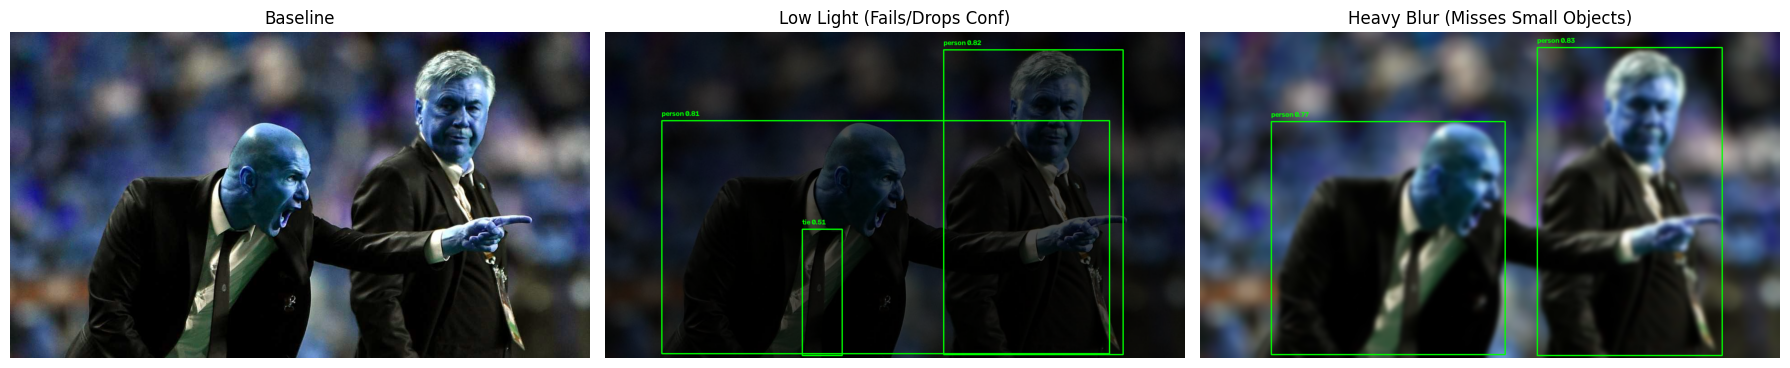

In [10]:
test_img = cv2.imread(img_path)

# Augmentations
dark_img = cv2.convertScaleAbs(test_img, alpha=0.3, beta=0) # Reduce contrast/brightness
blur_img = cv2.GaussianBlur(test_img, (31, 31), 0)

print("Running Stress Test...")
res_dark, _ = robust_detection_pipeline(dark_img)
res_blur, _ = robust_detection_pipeline(blur_img)

show_images_grid([test_img, res_dark, res_blur], 
                 ['Baseline', 'Low Light (Fails/Drops Conf)', 'Heavy Blur (Misses Small Objects)'], 
                 1, 3, figsize=(18, 6))